In [8]:
import os
import sys
from pathlib import Path

start = Path.cwd()
project_root = next(
    (path for path in (start, *start.parents)
     if (path / "src" / "engine.py").is_file()
     and (path / "materials" / "daily_returns.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this notebook from inside the pca-finance-local project.")

os.chdir(project_root)  # The project's data loader uses paths relative to the root.
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np

from src.data import load_daily_returns, load_tickers
from src.engine import Engine, ModelEntry
from src.models.factor import FactorModel
from src.models.pca import PCAModel
from src.modules.simulator import Simulator
from src.strategies.residual_snapback import ResidualSnapback

## Load the data

The return matrix has one row per trading day and one column per stock. The benchmark and snapback both rebalance on the last trading date of each week, using the same simulated fee.

In [9]:
daily_returns = load_daily_returns()
dates = daily_returns.dates
tickers = load_tickers()

monday = np.datetime64("1970-01-05")
weeks = (dates.astype("datetime64[D]") - monday) // np.timedelta64(7, "D")
rebalance_dates = dates[np.r_[weeks[:-1] != weeks[1:], True]]

print(f"{len(dates):,} days × {len(daily_returns.stock_ids):,} stocks")
print(f"{dates[0]} to {dates[-1]}")

6,037 days × 1,201 stocks
2000-01-03 to 2023-12-29


## Set up an experiment

The default strategy adds up the last three daily residuals for each stock and divides by the preceding 60-day residual volatility times the square root of three. It buys up to 20 of the lowest-scoring stocks with scores at or below −2, weighting them equally. The hedged run uses the same signal and selected stocks. At each rebalance it sets estimated exposure to all five components to zero, allowing short positions and targeting 100% gross exposure. It stays in cash when the projection produces no usable weights. Exposures can drift between rebalances.

The hybrid runs allocate 30%, 50%, or 70% to the original equal-weight portfolio and the remainder to the fully hedged portfolio. The stricter-cutoff run changes the score threshold.

Dynamic volatility uses the 30-trading-day standard deviation of daily equal-weight universe returns. At each rebalance it ranks the current reading against all earlier readings, counting each tie as half a reading below the current one. The percentile rank is the fraction allocated to the fully hedged portfolio, with the remainder allocated to the original portfolio. For example, the 75th percentile gives a 75% hedged and 25% original blend. It uses the original allocation until 252 earlier readings are available.

In [10]:
trade_fee = 0.0005  # Five basis points per unit traded.
hybrid_experiments = {
    f"Hybrid ({fraction:.0%} original)": {"hybrid": True, "hybrid_parameter": fraction}
    for fraction in (0.3, 0.5, 0.7)
}
experiments = {
    "Default snapback": {},
    "Hedged snapback": {"hedge_out_components": True},
    "Stricter cutoff": {"score_threshold": -2.5},
    **hybrid_experiments,
    "Dynamic volatility": {"dynamic_vol": True},
}

## Run the backtest

The saved Dynamic volatility results and plot use the previous hedge rule. Rerun the notebook to refresh them.

PCA estimates five common patterns from a 500-day window. The lagged factor model uses a PCA fit available through the prior trading day and a 100-day regression ending the prior day. It then uses today's returns to calculate today's residual. The simulator applies that day's returns to the positions already held before entering any new trades.

Every run starts with fresh models and portfolios.

In [11]:
class EqualWeightBenchmark:
    def __init__(self, rebalance_dates):
        self.rebalance_dates = frozenset(rebalance_dates)

    def update(self, timestamp, model_outputs, positions):
        if timestamp in self.rebalance_dates:
            return np.full_like(positions, 1.0 / positions.size)
        return positions


simulators = {}
for label, settings in experiments.items():
    strategy = ResidualSnapback(
        "lagged_factor",
        rebalance_dates,
        hedge_out_components=settings.get("hedge_out_components", False),
        hybrid=settings.get("hybrid", False),
        hybrid_parameter=settings.get("hybrid_parameter", 0.5),
        dynamic_vol=settings.get("dynamic_vol", False),
        daily_returns=daily_returns,
    )
    for name in ("signal_days", "volatility_days", "score_threshold", "max_positions"):
        if name in settings:
            setattr(strategy, name, settings[name])
    simulators[label] = Simulator(daily_returns, strategy, trade_fee)

simulators["Equal-weight benchmark"] = Simulator(
    daily_returns, EqualWeightBenchmark(rebalance_dates), trade_fee
)


engine = Engine(
    daily_returns=daily_returns,
    models=[
        ModelEntry("pca", PCAModel(5, 500, 5)),
        ModelEntry("lagged_factor", FactorModel("pca", 5, 100, 1, fit_lag=1)),
    ],
    modules=list(simulators.values()),
)
outputs = engine.run()
histories = {label: simulator.get_history() for label, simulator in simulators.items()}

## Compare performance

Each portfolio starts at 1. Drawdown measures how far its value has fallen below its previous high. The benchmark starts rebalancing in the first week, while snapback stays in cash until it has enough residual history.

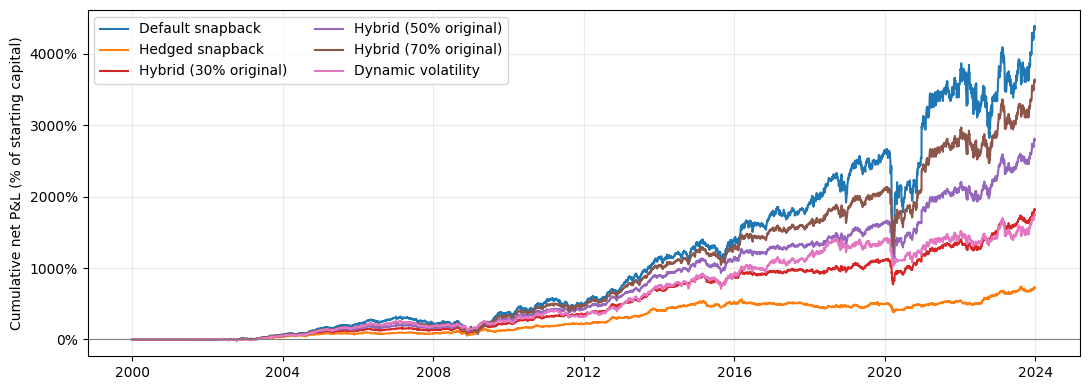

Default snapback | Net return 4342.95% | Annualized Sharpe 0.78 | Max drawdown -58.52% | Total turnover 2236.08×
Hedged snapback | Net return 726.79% | Annualized Sharpe 0.79 | Max drawdown -28.71% | Total turnover 2207.92×
Stricter cutoff | Net return 2084.61% | Annualized Sharpe 0.64 | Max drawdown -74.77% | Total turnover 2238.40×
Hybrid (30% original) | Net return 1813.56% | Annualized Sharpe 1.06 | Max drawdown -31.87% | Total turnover 1826.68×
Hybrid (50% original) | Net return 2790.46% | Annualized Sharpe 1.03 | Max drawdown -37.91% | Total turnover 1732.12×
Hybrid (70% original) | Net return 3609.57% | Annualized Sharpe 0.93 | Max drawdown -46.25% | Total turnover 1857.46×
Dynamic volatility | Net return 1735.21% | Annualized Sharpe 0.88 | Max drawdown -37.96% | Total turnover 2101.79×
Equal-weight benchmark | Net return 2539.35% | Annualized Sharpe 0.82 | Max drawdown -53.00% | Total turnover 40.64×


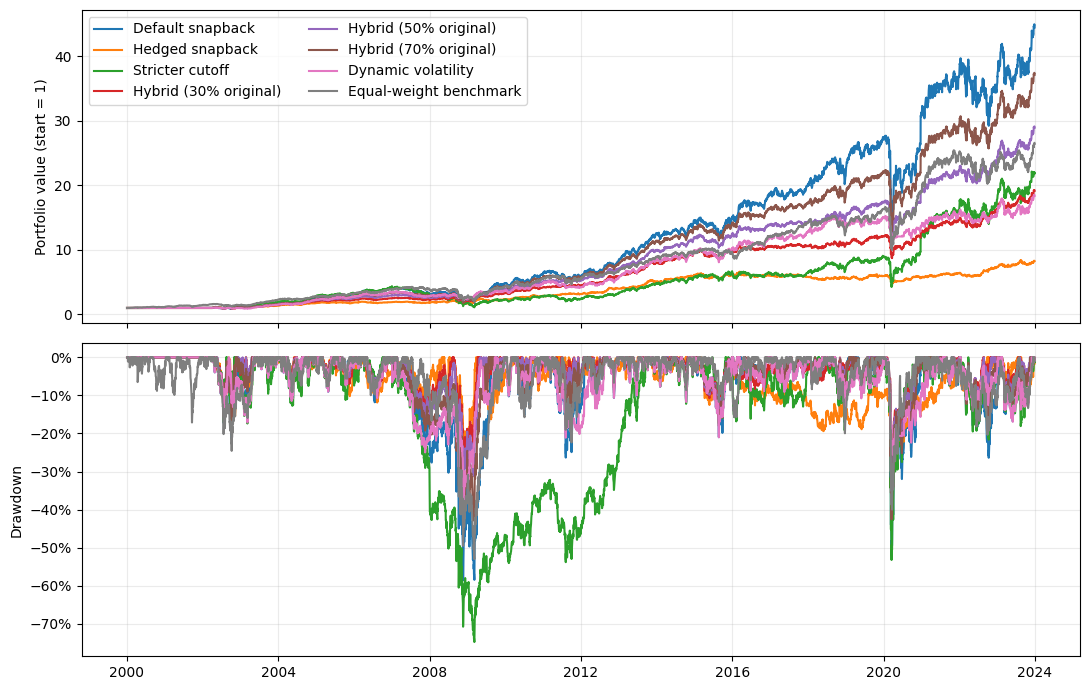

In [12]:
fig, pnl_ax = plt.subplots(figsize=(11, 4))
colors = {label: f"C{index}" for index, label in enumerate(histories)}
for label in ("Default snapback", "Hedged snapback", *hybrid_experiments, "Dynamic volatility"):
    value = histories[label].total_value
    pnl_ax.plot(dates, value[1:] - value[0], label=label, color=colors[label])
pnl_ax.set_ylabel("Cumulative net P&L (% of starting capital)")
pnl_ax.yaxis.set_major_formatter(PercentFormatter(1))
pnl_ax.axhline(0, color="gray", linewidth=0.8)
pnl_ax.legend(ncols=2)
pnl_ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

fig, (value_ax, drawdown_ax) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for label, history in histories.items():
    value = history.total_value
    daily_net_returns = value[1:] / value[:-1] - 1
    volatility = daily_net_returns.std(ddof=1)
    sharpe = np.sqrt(252) * daily_net_returns.mean() / volatility if volatility else np.nan
    drawdown = value / np.maximum.accumulate(value) - 1
    turnover = np.abs(history.trades).sum()

    print(
        f"{label} | Net return {value[-1] / value[0] - 1:.2%} | "
        f"Annualized Sharpe {sharpe:.2f} | Max drawdown {drawdown.min():.2%} | "
        f"Total turnover {turnover:.2f}×"
    )
    value_ax.plot(dates, value[1:], label=label, color=colors[label])
    drawdown_ax.plot(dates, drawdown[1:], color=colors[label])

value_ax.set_ylabel("Portfolio value (start = 1)")
value_ax.legend(ncols=2)
drawdown_ax.set_ylabel("Drawdown")
drawdown_ax.yaxis.set_major_formatter(PercentFormatter(1))
for ax in (value_ax, drawdown_ax):
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## See what the strategy held

The top panel counts positions held after each day's trades. The bottom panel shows weekly trading activity as a fraction of portfolio value. The strategy can hold fewer than 20 stocks when fewer qualify.

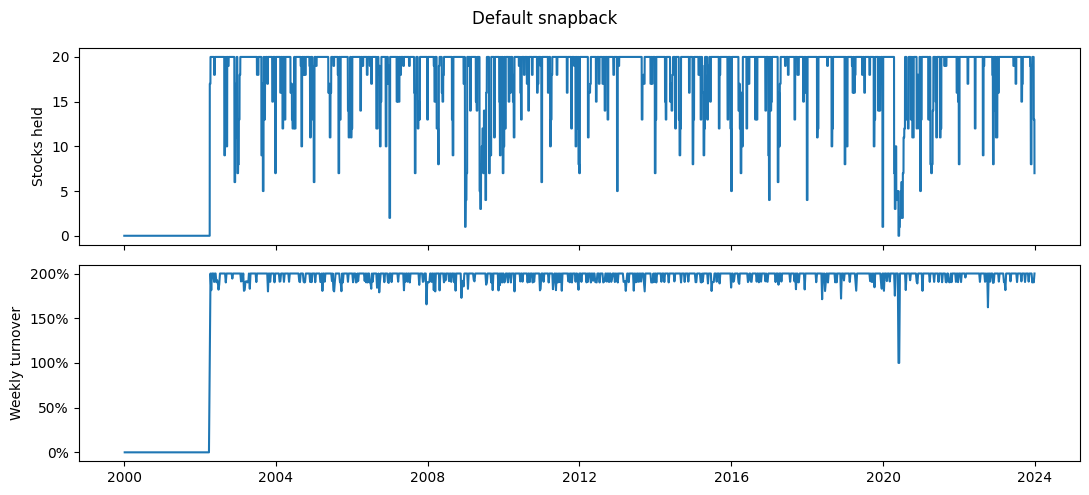

In [13]:
label = "Default snapback"
history = histories[label]
weekly_turnover = np.add.reduceat(
    np.abs(history.trades[1:]).sum(axis=1),
    np.flatnonzero(np.r_[True, weeks[1:] != weeks[:-1]]),
)
fig, (holdings_ax, turnover_ax) = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
holdings_ax.plot(dates, np.count_nonzero(history.positions[1:], axis=1))
holdings_ax.set_ylabel("Stocks held")
turnover_ax.plot(rebalance_dates, weekly_turnover)
turnover_ax.set_ylabel("Weekly turnover")
turnover_ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle(label)
fig.tight_layout()
plt.show()

## Follow one stock through the factor model

The factor model's estimate is the fitted intercept plus the contribution from the five common factors. The residual is the actual return minus that estimate. Shaded regions indicate when the selected portfolio held the stock after that day's trades. Try another ticker or date range to explore.

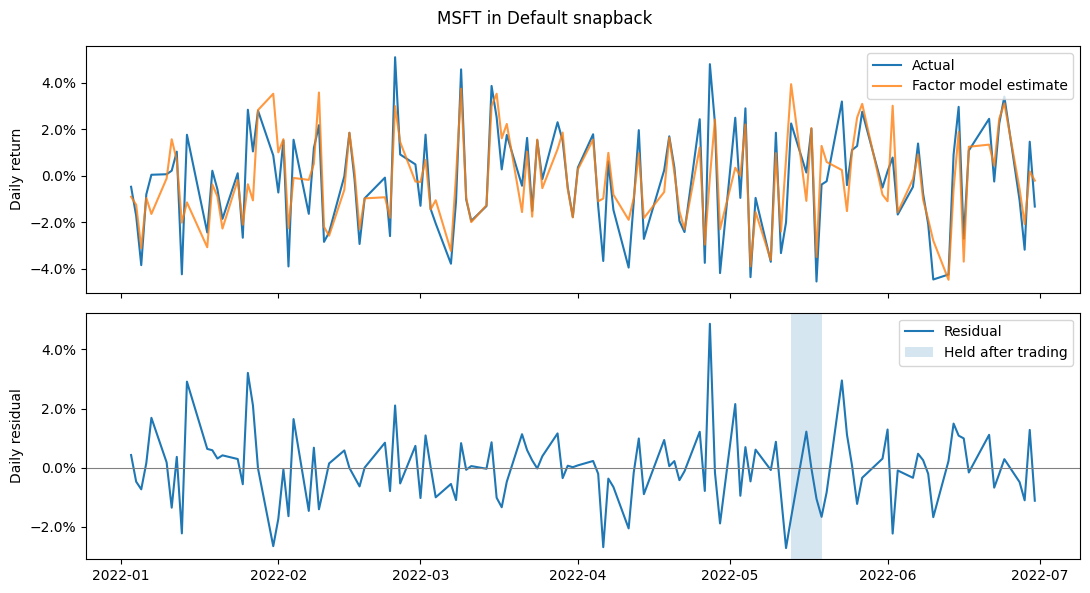

In [14]:
ticker = "MSFT"
start_date = np.datetime64("2022-01-01")
end_date = np.datetime64("2022-06-30")

matching_columns = [
    index for index, stock_id in enumerate(daily_returns.stock_ids)
    if tickers.get(int(stock_id)) == ticker.upper()
]
if len(matching_columns) != 1:
    raise ValueError(f"Expected one matching column for {ticker}, found {len(matching_columns)}.")

column = matching_columns[0]
in_range = (dates >= start_date) & (dates <= end_date)
if not in_range.any():
    raise ValueError("Choose a date range that overlaps the dataset.")

attributions = outputs["lagged_factor"]
actual = daily_returns.returns[in_range, column]
fitted = np.array([
    attribution.factor_intercept[column] + attribution.factor_projection[column]
    for attribution in attributions
])[in_range]
residual = actual - fitted
held = history.positions[1:, column][in_range] > 0

fig, (returns_ax, residual_ax) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
returns_ax.plot(dates[in_range], actual, label="Actual")
returns_ax.plot(dates[in_range], fitted, label="Factor model estimate", alpha=0.8)
returns_ax.set_ylabel("Daily return")
returns_ax.legend()
residual_ax.plot(dates[in_range], residual, label="Residual")
residual_ax.axhline(0, color="gray", linewidth=0.8)
if held.any():
    residual_ax.fill_between(
        dates[in_range], 0, 1, where=held, step="post",
        transform=residual_ax.get_xaxis_transform(), alpha=0.18, label="Held after trading",
    )
residual_ax.set_ylabel("Daily residual")
residual_ax.legend()
for ax in (returns_ax, residual_ax):
    ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle(f"{ticker.upper()} in {label}")
fig.tight_layout()
plt.show()